Experiment 3: Image Classification using a CNN

Aim: Build an image classification model in four stages: load and preprocess image data, define the architecture, train the model, and estimate performance.

Dataset: Fashion-MNIST (10 clothing categories), loaded using TensorFlow/Keras.

Stage 1 — Import packages and load the data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report

print('TensorFlow version:', tf.__version__)


TensorFlow version: 2.21.0


In [2]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print('Training images:', x_train.shape)
print('Training labels:', y_train.shape)
print('Test images:', x_test.shape)
print('Test labels:', y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


Fashion-MNIST images are 28 × 28 grayscale pixel arrays. Normalize pixel values to 0–1 and add a channel dimension required by the CNN.

In [3]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Add the grayscale channel dimension: (images, height, width, channels)
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print('Preprocessed training shape:', x_train.shape)
print('Preprocessed test shape:', x_test.shape)

Preprocessed training shape: (60000, 28, 28, 1)
Preprocessed test shape: (10000, 28, 28, 1)


Stage 2 — Define the CNN architecture

Convolution layers learn image features; max pooling reduces the spatial size; dense layers make the final class prediction.

In [4]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, kernel_size=3, activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Conv2D(64, kernel_size=3, activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Stage 3 — Train the model

In [5]:
history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=128,
    verbose=1
)

Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.7779 - loss: 0.6151 - val_accuracy: 0.8582 - val_loss: 0.3929
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8603 - loss: 0.3849 - val_accuracy: 0.8797 - val_loss: 0.3264
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8778 - loss: 0.3331 - val_accuracy: 0.8920 - val_loss: 0.2945
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8888 - loss: 0.3014 - val_accuracy: 0.8978 - val_loss: 0.2885
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8967 - loss: 0.2811 - val_accuracy: 0.9035 - val_loss: 0.2663
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.9038 - loss: 0.2602 - val_accuracy: 0.9073 - val_loss: 0.2558
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9110 - loss: 0.2426 - val_accuracy: 0.9110 - val_loss: 0.2473
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9153 - loss: 0.2289 - val_accuracy:

Stage 4 — Estimate model performance

Evaluate on the held-out test set, print precision/recall/F1, and inspect example predictions.

In [6]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')
print('\nClassification report:')
print(classification_report(y_test, predicted_labels, target_names=class_names, digits=4))

Test loss: 0.2761
Test accuracy: 0.9004

Classification report:
              precision    recall  f1-score   support

 T-shirt/top     0.8182    0.8910    0.8530      1000
     Trouser     0.9899    0.9770    0.9834      1000
    Pullover     0.8429    0.8690    0.8557      1000
       Dress     0.9006    0.9060    0.9033      1000
        Coat     0.8000    0.9120    0.8523      1000
      Sandal     0.9620    0.9870    0.9743      1000
       Shirt     0.8178    0.5790    0.6780      1000
     Sneaker     0.9563    0.9420    0.9491      1000
         Bag     0.9497    0.9810    0.9651      1000
  Ankle boot     0.9648    0.9600    0.9624      1000

    accuracy                         0.9004     10000
   macro avg     0.9002    0.9004    0.8977     10000
weighted avg     0.9002    0.9004    0.8977     10000



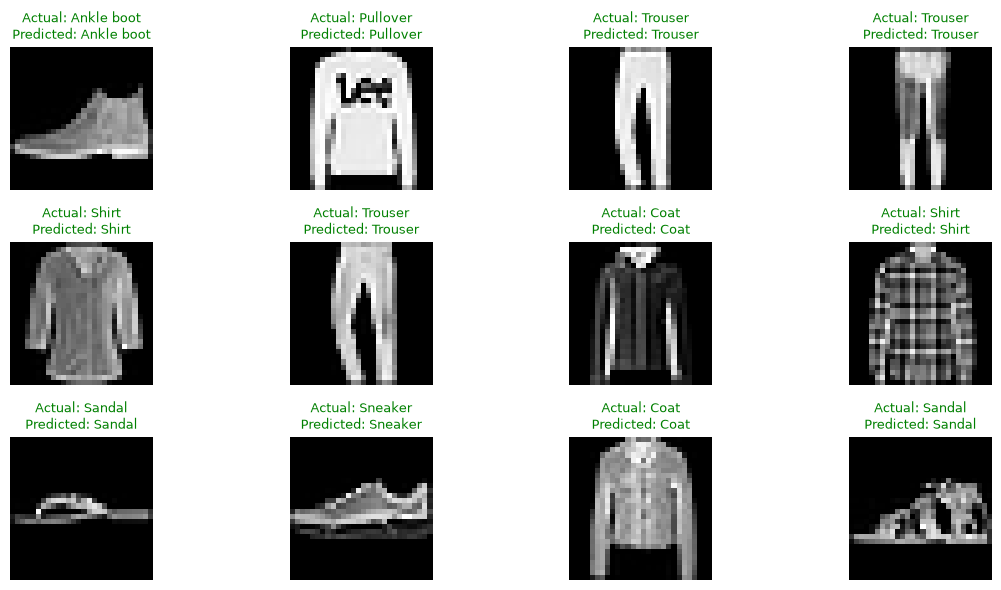

In [7]:
# Display 12 test examples with actual and predicted class names.
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    color = 'green' if predicted_labels[i] == y_test[i] else 'red'
    plt.title(f'Actual: {class_names[y_test[i]]}\nPredicted: {class_names[predicted_labels[i]]}', color=color, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

Training curves
The plots compare training and validation accuracy and loss across epochs.

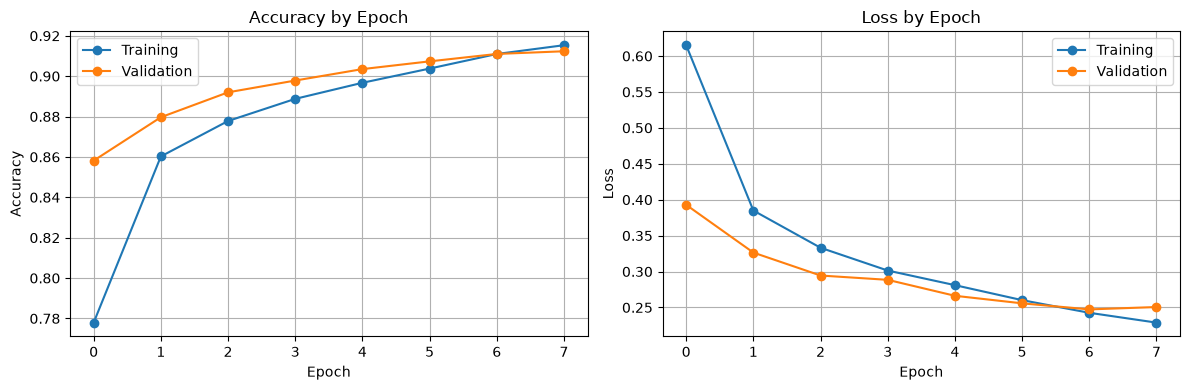

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'], marker='o', label='Training')
axes[0].plot(history.history['val_accuracy'], marker='o', label='Validation')
axes[0].set_title('Accuracy by Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['loss'], marker='o', label='Training')
axes[1].plot(history.history['val_loss'], marker='o', label='Validation')
axes[1].set_title('Loss by Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Result
The CNN was trained to classify Fashion-MNIST images. Record the test accuracy and loss printed above. The sample predictions and training curves show the model's performance.